In [34]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (classification_report, confusion_matrix, 
                             roc_curve, roc_auc_score, precision_recall_curve,
                             f1_score, precision_score, recall_score)
from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE


np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [35]:

# Loading the data
df = pd.read_csv('Bank Marketing_dataset/bank-additional-full.csv', sep=';')

print(f"Dataset shape: {df.shape}")
print(f"\nFirst 5 rows:")
df.head()


Dataset shape: (41188, 21)

First 5 rows:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [36]:
# for data analysis 

def load_data(filepath='Bank Marketing_dataset/bank-additional-full.csv'):
    """Load the bank marketing dataset"""
    df = pd.read_csv(filepath, sep=';')
    print(f"Loaded {len(df)} rows, {len(df.columns)} columns")
    return df

def get_data_summary(df):
    """Print the main dataset checks used in this analysis"""
    print("DATASET SUMMARY")
    
    print(f"\nShape: {df.shape}")
    print(f"\nColumns: {list(df.columns)}")
    
    print("\nData Types:")
    print(df.dtypes.value_counts())
    
    print("\nMissing values (coded as 'unknown'):")
    for col in df.columns:
        unknown_count = (df[col] == 'unknown').sum()
        if unknown_count > 0:
            print(f"  {col}: {unknown_count} ({unknown_count/len(df)*100:.2f}%)")
    
    print("\nTarget Distribution:")
    print(df['y'].value_counts())
    print(f"\nPositive rate: {df['y'].value_counts(normalize=True)['yes']*100:.2f}%")

def plot_class_distribution(df):
    """Plot the class distribution of target variable"""
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x='y')
    plt.title('Class Distribution')
    plt.xlabel('Subscribed to term deposit?')
    plt.ylabel('Count')
    plt.show()

def plot_numeric_by_target(df, numeric_cols, target='y'):
    """Plot boxplots of numeric features by target"""
    n_cols = 3
    n_rows = (len(numeric_cols) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(numeric_cols):
        sns.boxplot(data=df, x=target, y=col, ax=axes[i])
        axes[i].set_title(f'{col} by {target}')
    
    # Hide unused subplots
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

def get_categorical_crosstab(df, categorical_cols, target='y'):
    results = {}
    for col in categorical_cols:
        cross_tab = pd.crosstab(df[col], df[target], normalize='index') * 100
        results[col] = cross_tab
    return results

if __name__ == "__main__":
    df = load_data()
    get_data_summary(df)

Loaded 41188 rows, 21 columns
DATASET SUMMARY

Shape: (41188, 21)

Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data Types:
str        11
int64       5
float64     5
Name: count, dtype: int64

Missing values (coded as 'unknown'):
  job: 330 (0.80%)
  marital: 80 (0.19%)
  education: 1731 (4.20%)
  default: 8597 (20.87%)
  housing: 990 (2.40%)
  loan: 990 (2.40%)

Target Distribution:
y
no     36548
yes     4640
Name: count, dtype: int64

Positive rate: 11.27%


In [37]:
# Checking the basic info
print("Dataset Info:")
df.info()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-nu

In [38]:
# Checking for missing values (coded as 'unknown')
print("\nMissing values (coded as 'unknown') per column:")
for col in df.columns:
    unknown_count = (df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f"  {col}: {unknown_count} ({unknown_count/len(df)*100:.2f}%)")


Missing values (coded as 'unknown') per column:
  job: 330 (0.80%)
  marital: 80 (0.19%)
  education: 1731 (4.20%)
  default: 8597 (20.87%)
  housing: 990 (2.40%)
  loan: 990 (2.40%)



Target variable distribution:
y
no     36548
yes     4640
Name: count, dtype: int64

Percentage: 11.27% positive (yes), 88.73% negative (no)


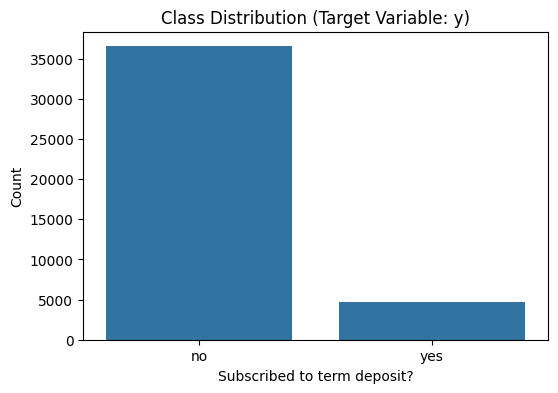

In [39]:
# Checking the target variable distribution
print("\nTarget variable distribution:")
target_counts = df['y'].value_counts()
print(target_counts)
print(f"\nPercentage: {target_counts['yes']/len(df)*100:.2f}% positive (yes), {target_counts['no']/len(df)*100:.2f}% negative (no)")

# Visualising class imbalance
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='y')
plt.title('Class Distribution (Target Variable: y)')
plt.xlabel('Subscribed to term deposit?')
plt.ylabel('Count')
plt.show()

In [40]:

# EXPLORATORY DATA ANALYSIS (EDA)

# Numeric features distribution
numeric_cols = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 
                'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

print("Numeric features summary:")
df[numeric_cols].describe()

Numeric features summary:


,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


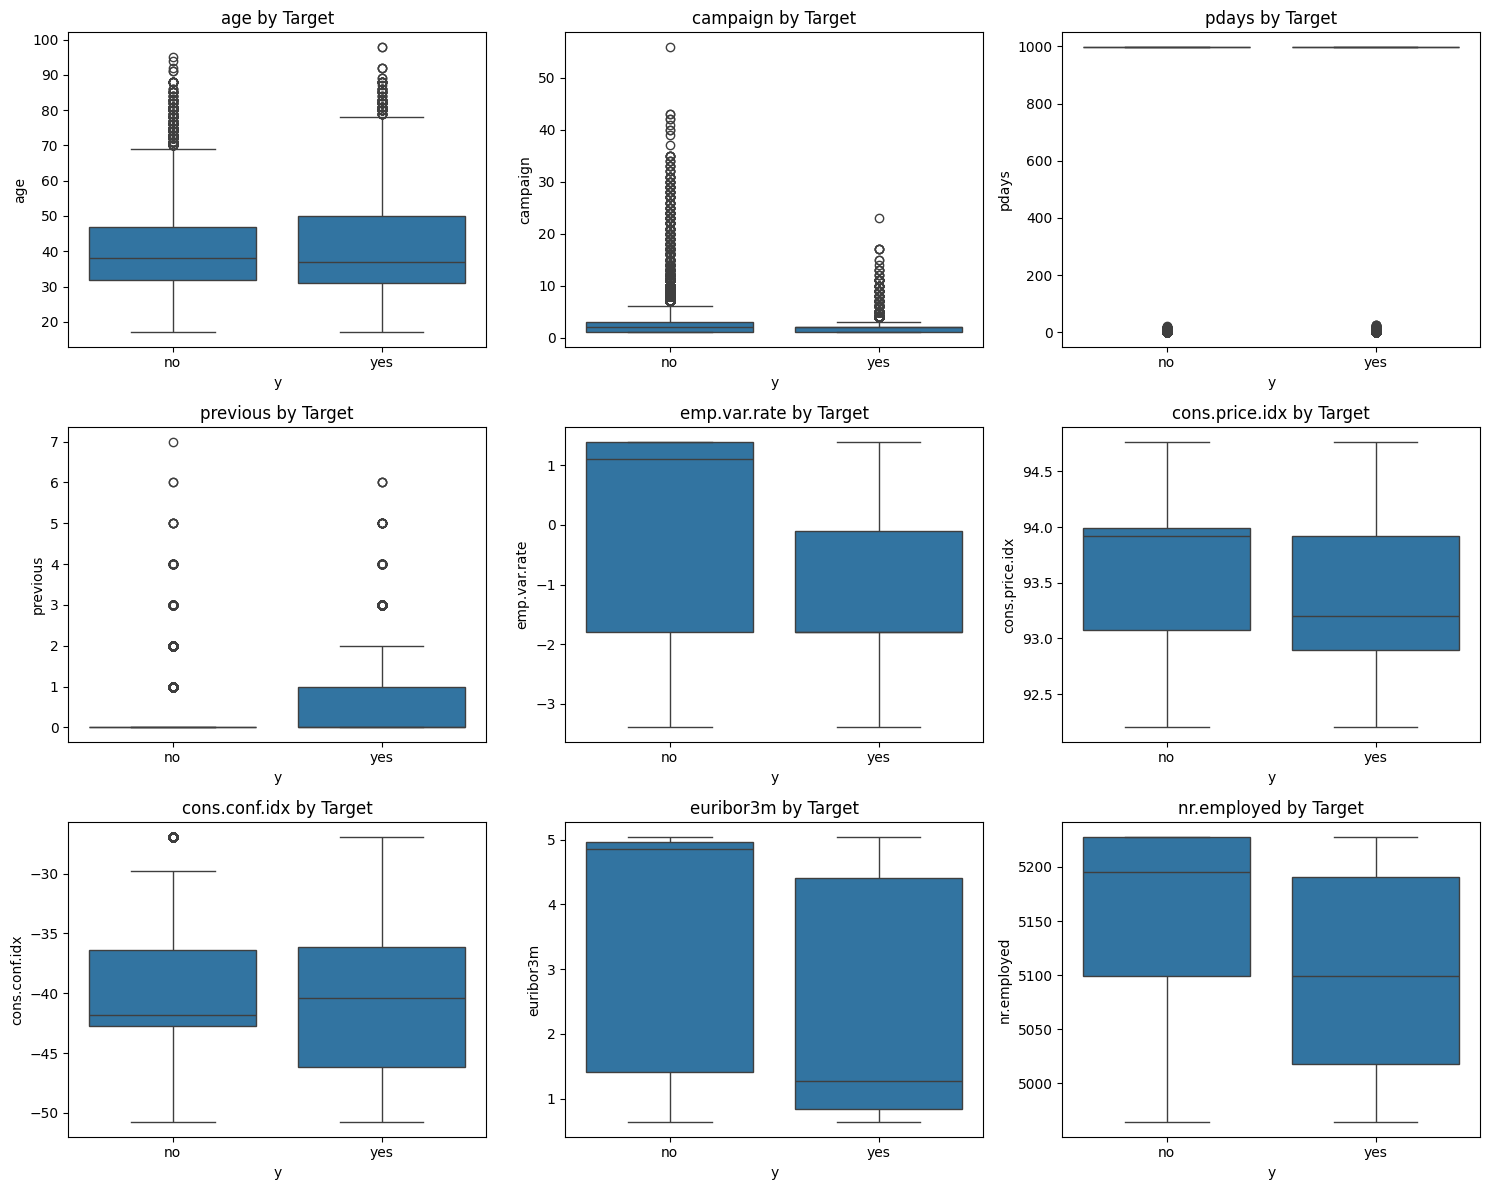

In [41]:
# Visualise numeric features by target
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='y', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Target')

plt.tight_layout()
plt.show()

In [42]:
# Categorical features analysis
categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 
                    'loan', 'contact', 'month', 'day_of_week', 'poutcome']

print("Categorical features - Relationship with target:")
for col in categorical_cols:
    print(f"\n{col}:")
    cross_tab = pd.crosstab(df[col], df['y'], normalize='index') * 100
    print(cross_tab.head())

Categorical features - Relationship with target:

job:
y                    no        yes
job                               
admin.        87.027442  12.972558
blue-collar   93.105684   6.894316
entrepreneur  91.483516   8.516484
housemaid     90.000000  10.000000
management    88.782490  11.217510

marital:
y                no        yes
marital                       
divorced  89.679098  10.320902
married   89.842747  10.157253
single    85.995851  14.004149
unknown   85.000000  15.000000

education:
y                   no        yes
education                        
basic.4y     89.750958  10.249042
basic.6y     91.797557   8.202443
basic.9y     92.175352   7.824648
high.school  89.164477  10.835523
illiterate   77.777778  22.222222

default:
y                no        yes
default                       
no        87.121026  12.878974
unknown   94.847040   5.152960
yes      100.000000   0.000000

housing:
y               no        yes
housing                      
no       89.120395 

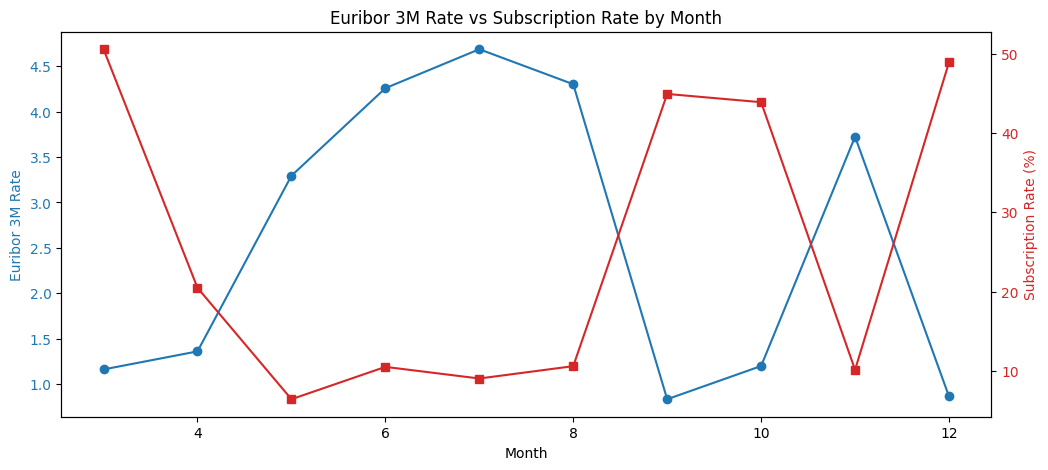

In [43]:
# Economic indicators over time (if month is ordered)
# Convert month to numeric order
month_order = {'mar':3, 'apr':4, 'may':5, 'jun':6, 'jul':7, 'aug':8, 
               'sep':9, 'oct':10, 'nov':11, 'dec':12, 'jan':1, 'feb':2}
df['month_num'] = df['month'].map(month_order)

# Plot euribor3m and subscription rate over time
fig, ax1 = plt.subplots(figsize=(12, 5))

# Group by month
monthly_data = df.groupby('month_num').agg({
    'euribor3m': 'mean',
    'y': lambda x: (x == 'yes').mean() * 100
}).reset_index().sort_values('month_num')

ax1.set_xlabel('Month')
ax1.set_ylabel('Euribor 3M Rate', color='tab:blue')
ax1.plot(monthly_data['month_num'], monthly_data['euribor3m'], marker='o', color='tab:blue', label='Euribor 3M')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Subscription Rate (%)', color='tab:red')
ax2.plot(monthly_data['month_num'], monthly_data['y'], marker='s', color='tab:red', label='Subscription %')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Euribor 3M Rate vs Subscription Rate by Month')
plt.show()

In [44]:
# DATA PREPROCESSING

print("Dropping 'duration' column as it's not known before a call...")
df = df.drop('duration', axis=1)
print(f"Shape after dropping duration: {df.shape}")

# Separate features and target
X = df.drop('y', axis=1)
y = df['y'].map({'yes': 1, 'no': 0})  # Convert to binary

print(f"\nFeatures shape: {X.shape}")
print(f"Target distribution: {y.value_counts().to_dict()}")

Dropping 'duration' column as it's not known before a call...
Shape after dropping duration: (41188, 21)

Features shape: (41188, 20)
Target distribution: {0: 36548, 1: 4640}


In [45]:
# Identify numeric and categorical columns (excluding duration)
numeric_features = ['age', 'campaign', 'pdays', 'previous', 
                    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 
                    'euribor3m', 'nr.employed']

categorical_features = ['job', 'marital', 'education', 'default', 
                        'housing', 'loan', 'contact', 'month', 
                        'day_of_week', 'poutcome']

print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [46]:
# Create preprocessing pipeline
# For numeric features: StandardScaler
# For categorical features: OneHotEncoder (handle_unknown='ignore' for test set)

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [47]:
# Split data into train and test sets (stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
print(f"Training set class distribution: {y_train.value_counts().to_dict()}")
print(f"Test set class distribution: {y_test.value_counts().to_dict()}")

Training set size: 32950
Test set size: 8238
Training set class distribution: {0: 29238, 1: 3712}
Test set class distribution: {0: 7310, 1: 928}


In [16]:
# HANDLING IMBALANCED DATA


# Calculate class weights
classes = np.array([0, 1])
class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

print(f"Class weights: {class_weight_dict}")
print(f"This gives more weight to the minority class ('yes' subscription)")

Class weights: {0: np.float64(0.5634790341336616), 1: np.float64(4.438308189655173)}
This gives more weight to the minority class ('yes' subscription)


In [48]:
# RANDOM FOREST WITH OOB TUNING

# Function to train Random Forest with OOB evaluation
def train_rf_with_oob(n_estimators, max_depth, min_samples_split, max_features, 
                       X_train, y_train, class_weight):
    """Train Random Forest and return OOB score"""
    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        max_features=max_features,
        class_weight=class_weight,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    )
    
    # Apply preprocessing and train
    X_train_processed = preprocessor.fit_transform(X_train)
    rf.fit(X_train_processed, y_train)
    
    return rf.oob_score_

# Parameter grid for tuning
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2', None]
}

print("Starting OOB-based hyperparameter tuning...")
print("This may take a few minutes.\n")

# Track best parameters
best_params = None
best_oob_score = 0
results = []

# I used a small manual grid search with OOB score for tunning
for n_est in param_grid['n_estimators']:
    for depth in param_grid['max_depth']:
        for min_split in param_grid['min_samples_split']:
            for max_feat in param_grid['max_features']:
                oob_score = train_rf_with_oob(
                    n_est, depth, min_split, max_feat, 
                    X_train, y_train, class_weight_dict
                )
                results.append({
                    'n_estimators': n_est,
                    'max_depth': depth,
                    'min_samples_split': min_split,
                    'max_features': max_feat,
                    'oob_score': oob_score
                })
                
                if oob_score > best_oob_score:
                    best_oob_score = oob_score
                    best_params = {
                        'n_estimators': n_est,
                        'max_depth': depth,
                        'min_samples_split': min_split,
                        'max_features': max_feat
                    }
                
                print(f"n_est={n_est}, depth={depth}, min_split={min_split}, "
                      f"max_feat={max_feat} -> OOB: {oob_score:.4f}")

print(f"\n{'='*50}")
print(f"Best OOB Score: {best_oob_score:.4f}")
print(f"Best Parameters: {best_params}")

Starting OOB-based hyperparameter tuning...
This may take a few minutes.

n_est=50, depth=5, min_split=2, max_feat=sqrt -> OOB: 0.8274
n_est=50, depth=5, min_split=2, max_feat=log2 -> OOB: 0.7954
n_est=50, depth=5, min_split=2, max_feat=None -> OOB: 0.8452
n_est=50, depth=5, min_split=5, max_feat=sqrt -> OOB: 0.8240
n_est=50, depth=5, min_split=5, max_feat=log2 -> OOB: 0.8041
n_est=50, depth=5, min_split=5, max_feat=None -> OOB: 0.8452
n_est=50, depth=5, min_split=10, max_feat=sqrt -> OOB: 0.8240
n_est=50, depth=5, min_split=10, max_feat=log2 -> OOB: 0.8095
n_est=50, depth=5, min_split=10, max_feat=None -> OOB: 0.8451
n_est=50, depth=10, min_split=2, max_feat=sqrt -> OOB: 0.8495
n_est=50, depth=10, min_split=2, max_feat=log2 -> OOB: 0.8453
n_est=50, depth=10, min_split=2, max_feat=None -> OOB: 0.8582
n_est=50, depth=10, min_split=5, max_feat=sqrt -> OOB: 0.8513
n_est=50, depth=10, min_split=5, max_feat=log2 -> OOB: 0.8451
n_est=50, depth=10, min_split=5, max_feat=None -> OOB: 0.8582
n_

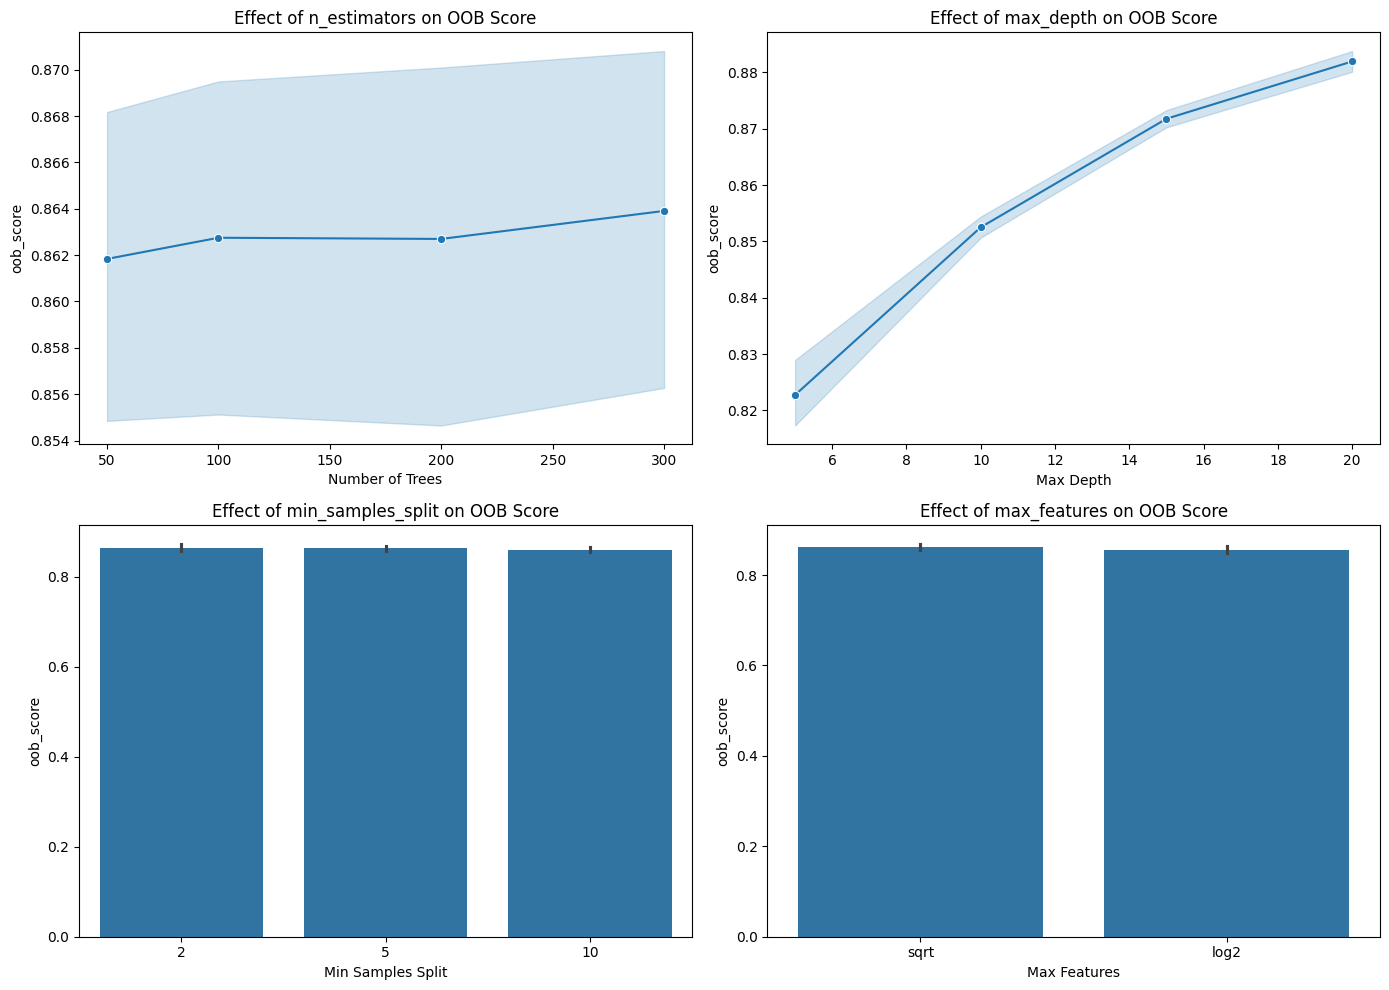

In [49]:
# Visualise OOB tuning results
results_df = pd.DataFrame(results)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Plot 1: n_estimators vs OOB score
sns.lineplot(data=results_df, x='n_estimators', y='oob_score', 
             marker='o', ax=axes[0])
axes[0].set_title('Effect of n_estimators on OOB Score')
axes[0].set_xlabel('Number of Trees')

# Plot 2: max_depth vs OOB score
sns.lineplot(data=results_df, x='max_depth', y='oob_score', 
             marker='o', ax=axes[1])
axes[1].set_title('Effect of max_depth on OOB Score')
axes[1].set_xlabel('Max Depth')

# Plot 3: min_samples_split vs OOB score
sns.barplot(data=results_df, x='min_samples_split', y='oob_score', ax=axes[2])
axes[2].set_title('Effect of min_samples_split on OOB Score')
axes[2].set_xlabel('Min Samples Split')

# Plot 4: max_features vs OOB score
sns.barplot(data=results_df, x='max_features', y='oob_score', ax=axes[3])
axes[3].set_title('Effect of max_features on OOB Score')
axes[3].set_xlabel('Max Features')

plt.tight_layout()
plt.show()

In [50]:

# TRAIN FINAL MODEL WITH BEST PARAMETERS

print("Training final Random Forest with best parameters...")

final_rf = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    max_features=best_params['max_features'],
    class_weight=class_weight_dict,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Apply preprocessing and train
X_train_processed = preprocessor.fit_transform(X_train)
final_rf.fit(X_train_processed, y_train)

print(f"Final model OOB Score: {final_rf.oob_score_:.4f}")

Training final Random Forest with best parameters...
Final model OOB Score: 0.8914


In [20]:

# MODEL EVALUATION

# Process test data
X_test_processed = preprocessor.transform(X_test)

# Make predictions
y_pred = final_rf.predict(X_test_processed)
y_pred_proba = final_rf.predict_proba(X_test_processed)[:, 1]

# Calculate metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("="*60)
print("MODEL PERFORMANCE ON TEST SET")
print("="*60)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))

MODEL PERFORMANCE ON TEST SET
Precision: 0.5668
Recall:    0.3017
F1-Score:  0.3938
ROC-AUC:   0.7796

Detailed Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7310
         Yes       0.57      0.30      0.39       928

    accuracy                           0.90      8238
   macro avg       0.74      0.64      0.67      8238
weighted avg       0.88      0.90      0.88      8238



In [51]:

# THRESHOLD TUNING

# Calculate precision, recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Calculate F1 for each threshold (excluding the last point where threshold is undefined)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)

# Find threshold that gives best F1 score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("="*60)
print("THRESHOLD TUNING RESULTS")
print("="*60)
print(f"Original threshold (0.5) - F1: {f1_score(y_test, y_pred):.4f}")
print(f"Best threshold found: {best_threshold:.3f}")
print(f"Best possible F1 at that threshold: {f1_scores[best_idx]:.4f}")

# Apply the best threshold
y_pred_tuned = (y_pred_proba >= best_threshold).astype(int)

# Calculate new metrics
new_precision = precision_score(y_test, y_pred_tuned)
new_recall = recall_score(y_test, y_pred_tuned)
new_f1 = f1_score(y_test, y_pred_tuned)
new_roc_auc = roc_auc_score(y_test, y_pred_proba)  # ROC-AUC doesn't change with threshold

print("\nPERFORMANCE WITH OPTIMIZED THRESHOLD:")
print(f"Precision: {new_precision:.4f} (was {precision:.4f})")
print(f"Recall:    {new_recall:.4f} (was {recall:.4f})")
print(f"F1-Score:  {new_f1:.4f} (was {f1:.4f})")

THRESHOLD TUNING RESULTS
Original threshold (0.5) - F1: 0.3938
Best threshold found: 0.310
Best possible F1 at that threshold: 0.4790

PERFORMANCE WITH OPTIMIZED THRESHOLD:
Precision: 0.4785 (was 0.5668)
Recall:    0.4795 (was 0.3017)
F1-Score:  0.4790 (was 0.3938)


In [52]:

# SMOTE - HANDLE IMBALANCE WITH SYNTHETIC DATA

from imblearn.over_sampling import SMOTE

print("="*60)
print("SMOTE RESULTS")
print("="*60)

# Apply SMOTE to training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

print(f"Original training size: {len(X_train_processed)}")
print(f"SMOTE training size: {len(X_train_smote)}")
print(f"Original 'yes' count: {sum(y_train)}")
print(f"SMOTE 'yes' count: {sum(y_train_smote)}")

# Train Random Forest on SMOTE-balanced data
rf_smote = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    max_features=best_params['max_features'],
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

# Evaluate SMOTE model
y_pred_smote = rf_smote.predict(X_test_processed)
y_pred_proba_smote = rf_smote.predict_proba(X_test_processed)[:, 1]

smote_precision = precision_score(y_test, y_pred_smote)
smote_recall = recall_score(y_test, y_pred_smote)
smote_f1 = f1_score(y_test, y_pred_smote)
smote_auc = roc_auc_score(y_test, y_pred_proba_smote)

print("\nSMOTE MODEL PERFORMANCE:")
print(f"Precision: {smote_precision:.4f}")
print(f"Recall:    {smote_recall:.4f}")
print(f"F1-Score:  {smote_f1:.4f}")
print(f"ROC-AUC:   {smote_auc:.4f}")

SMOTE RESULTS
Original training size: 32950
SMOTE training size: 58476
Original 'yes' count: 3712
SMOTE 'yes' count: 29238

SMOTE MODEL PERFORMANCE:
Precision: 0.4985
Recall:    0.3481
F1-Score:  0.4099
ROC-AUC:   0.7723


FINAL MODEL COMPARISON
                Model  Precision   Recall  F1-Score  ROC-AUC
          Original RF   0.566802 0.301724  0.393812 0.779635
RF + Threshold Tuning   0.478495 0.479526  0.479010 0.779635
           RF + SMOTE   0.498457 0.348060  0.409898 0.772334

Best model: RF + Threshold Tuning (F1-Score = 0.4790)


/var/folders/rm/6422ry7x66v81s8xt_tpmdk80000gn/T/ipykernel_31167/1943165778.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=15)


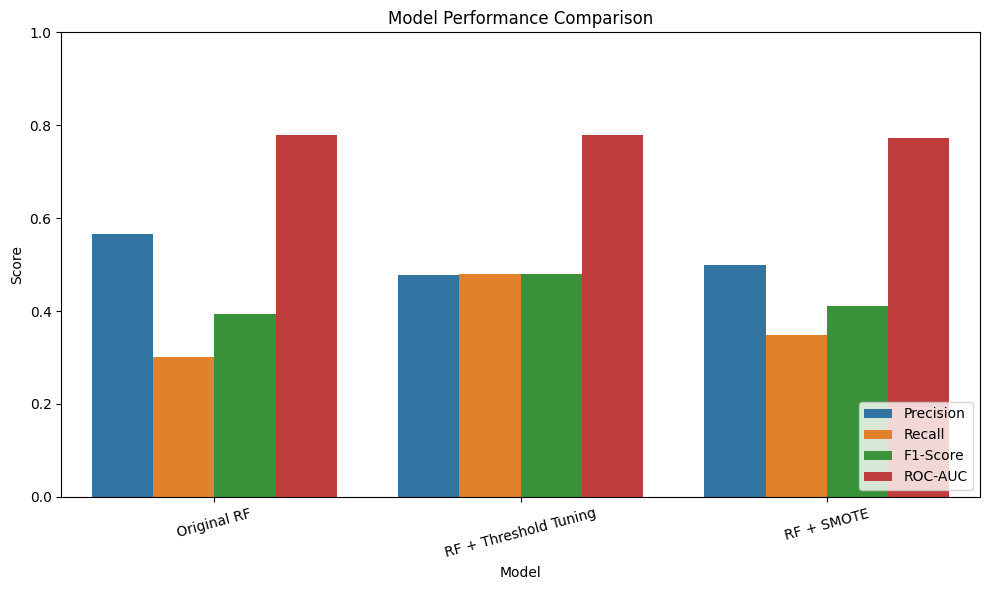

In [53]:
# FINAL COMPARISON - ALL MODELS

print("="*60)
print("FINAL MODEL COMPARISON")
print("="*60)

comparison_data = {
    'Model': ['Original RF', 'RF + Threshold Tuning', 'RF + SMOTE'],
    'Precision': [precision, new_precision, smote_precision],
    'Recall': [recall, new_recall, smote_recall],
    'F1-Score': [f1, new_f1, smote_f1],
    'ROC-AUC': [roc_auc, new_roc_auc, smote_auc]
}

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Find best model by F1 score
best_idx = comparison_df['F1-Score'].idxmax()
best_model = comparison_df.loc[best_idx, 'Model']
best_f1 = comparison_df.loc[best_idx, 'F1-Score']

print(f"\n{'='*60}")
print(f"Best model: {best_model} (F1-Score = {best_f1:.4f})")
print(f"{'='*60}")

# Visual comparison
fig, ax = plt.subplots(figsize=(10, 6))
comparison_melted = comparison_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
sns.barplot(data=comparison_melted, x='Model', y='Score', hue='Metric', ax=ax)
ax.set_title('Model Performance Comparison')
ax.set_ylim(0, 1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

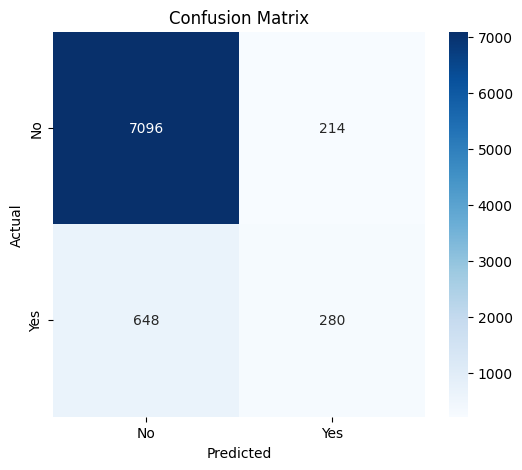


True Negatives: 7096
False Positives: 214
False Negatives: 648
True Positives: 280


In [54]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print(f"\nTrue Negatives: {cm[0,0]}")
print(f"False Positives: {cm[0,1]}")
print(f"False Negatives: {cm[1,0]}")
print(f"True Positives: {cm[1,1]}")

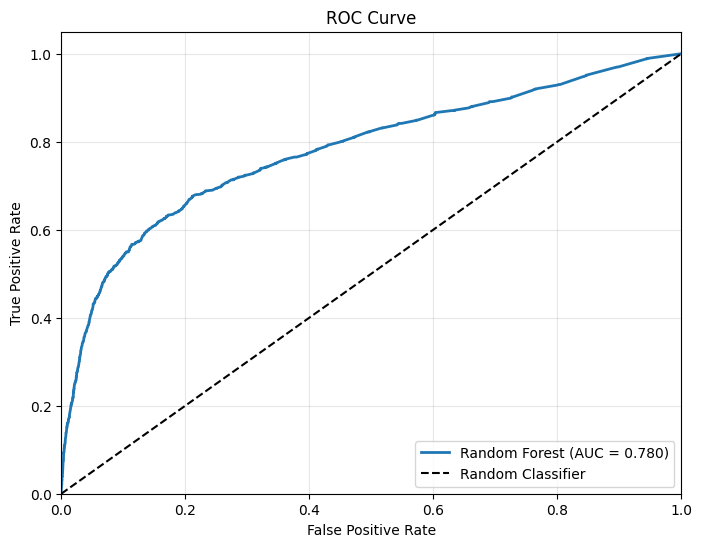

In [55]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

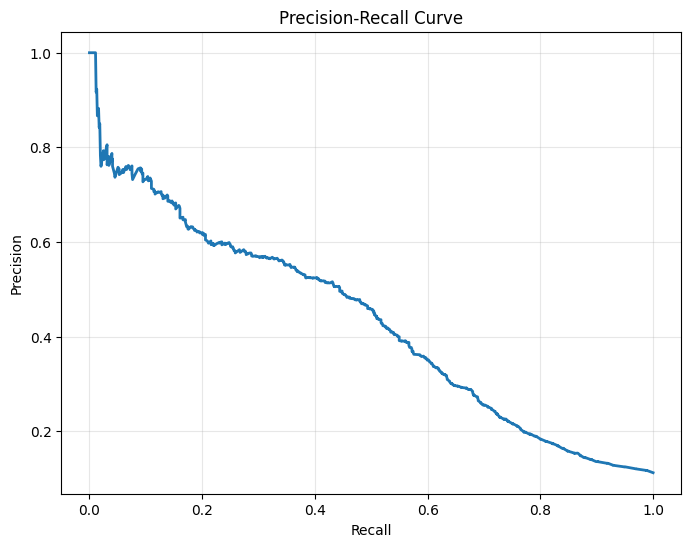

In [56]:
# Precision-Recall Curve
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_pred_proba)

plt.figure(figsize=(8,6))
plt.plot(recall_curve, precision_curve, linewidth=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(alpha=0.3)
plt.show()

In [57]:
# FEATURE IMPORTANCE ANALYSIS

# Get feature names after preprocessing
feature_names = (numeric_features + 
                 list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)))

importances = final_rf.feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print("Top 20 Most Important Features:")
print(feature_importance_df.head(20))

Top 20 Most Important Features:
                        feature  importance
8                   nr.employed    0.202205
0                           age    0.152283
7                     euribor3m    0.092949
1                      campaign    0.073186
6                 cons.conf.idx    0.043334
9                    job_admin.    0.016989
36                   housing_no    0.016321
28        education_high.school    0.015866
31  education_university.degree    0.015721
38                  housing_yes    0.015463
55              day_of_week_mon    0.014374
18               job_technician    0.014294
22              marital_married    0.013947
27           education_basic.9y    0.013754
54              day_of_week_fri    0.013700
23               marital_single    0.013568
10              job_blue-collar    0.013455
58              day_of_week_wed    0.013329
56              day_of_week_thu    0.012664
5                cons.price.idx    0.012657


/var/folders/rm/6422ry7x66v81s8xt_tpmdk80000gn/T/ipykernel_31167/1818026048.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_features, y='feature', x='importance', palette='viridis')


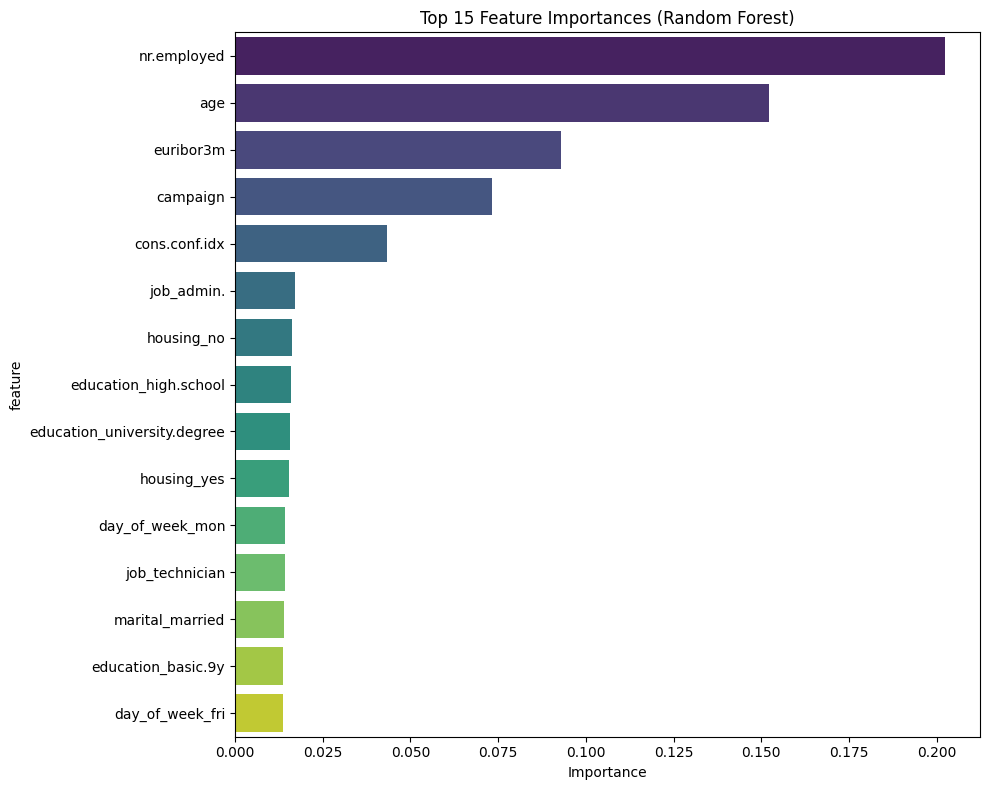

In [58]:
# Visualise top 15 features
plt.figure(figsize=(10, 8))
top_features = feature_importance_df.head(15)
sns.barplot(data=top_features, y='feature', x='importance', palette='viridis')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [59]:
# COMPARISON WITH BASELINE MODELS


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Logistic Regression (with class_weight)
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_processed, y_train)
y_pred_lr = lr.predict(X_test_processed)
y_pred_proba_lr = lr.predict_proba(X_test_processed)[:, 1]

# Decision Tree (with class_weight)
dt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dt.fit(X_train_processed, y_train)
y_pred_dt = dt.predict(X_test_processed)
y_pred_proba_dt = dt.predict_proba(X_test_processed)[:, 1]

# Compare metrics
models = {
    'Logistic Regression': (y_pred_lr, y_pred_proba_lr),
    'Decision Tree': (y_pred_dt, y_pred_proba_dt),
    'Random Forest (OOB-tuned)': (y_pred, y_pred_proba)
}

comparison_results = []
for name, (pred, proba) in models.items():
    comparison_results.append({
        'Model': name,
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba)
    })

comparison_df = pd.DataFrame(comparison_results)
print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)
print(comparison_df.to_string(index=False))


MODEL COMPARISON
                    Model  Precision   Recall  F1-Score  ROC-AUC
      Logistic Regression   0.367872 0.646552  0.468933 0.800942
            Decision Tree   0.328342 0.330819  0.329576 0.622883
Random Forest (OOB-tuned)   0.566802 0.301724  0.393812 0.779635


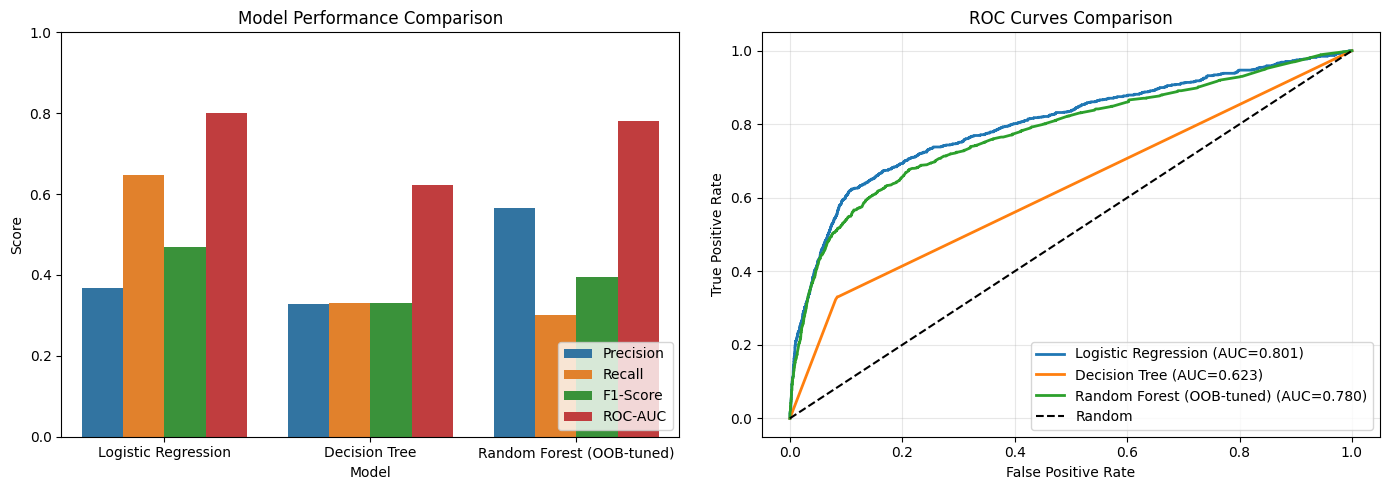

In [60]:
# Visualise model comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart comparison
comparison_melted = comparison_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
sns.barplot(data=comparison_melted, x='Model', y='Score', hue='Metric', ax=axes[0])
axes[0].set_title('Model Performance Comparison')
axes[0].set_ylim(0, 1)
axes[0].legend(loc='lower right')

# ROC curves comparison
for name, (_, proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', linewidth=2)

axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves Comparison')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [61]:

# SUMMARY AND CONCLUSIONS

print("\n" + "="*60)
print("SUMMARY OF FINDINGS")
print("="*60)

print(f"\n1. Dataset: {len(df)} instances, {X.shape[1]} features (excluding duration)")
print(f"2. Class imbalance: {target_counts['yes']/len(df)*100:.2f}% positive class")
print(f"3. Best OOB Score: {best_oob_score:.4f}")
print(f"4. Best Hyperparameters: {best_params}")
print(f"\n5. Final Test Performance:")
print(f"   - Precision: {precision:.4f}")
print(f"   - Recall: {recall:.4f}")
print(f"   - F1-Score: {f1:.4f}")
print(f"   - ROC-AUC: {roc_auc:.4f}")

print(f"\n6. Top 5 Most Important Features:")
for i, row in feature_importance_df.head(5).iterrows():
    print(f"   - {row['feature']}: {row['importance']:.4f}")

print("\nI focused on F1-score because the dataset is imbalanced and accuracy alone would be misleading.")
print("\n7. Key Insight: Economic indicators (euribor3m, emp.var.rate, nr.employed)")
print("   appear to be strong predictors alongside client demographics.")


SUMMARY OF FINDINGS

1. Dataset: 41188 instances, 20 features (excluding duration)
2. Class imbalance: 11.27% positive class
3. Best OOB Score: 0.8914
4. Best Hyperparameters: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 2, 'max_features': None}

5. Final Test Performance:
   - Precision: 0.5668
   - Recall: 0.3017
   - F1-Score: 0.3938
   - ROC-AUC: 0.7796

6. Top 5 Most Important Features:
   - nr.employed: 0.2022
   - age: 0.1523
   - euribor3m: 0.0929
   - campaign: 0.0732
   - cons.conf.idx: 0.0433

I focused on F1-score because the dataset is imbalanced and accuracy alone would be misleading.

7. Key Insight: Economic indicators (euribor3m, emp.var.rate, nr.employed)
   appear to be strong predictors alongside client demographics.


In [62]:
# Save the model for later use
# Save the preprocessor and model
joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(final_rf, 'random_forest_model.pkl')
print("\nModel and preprocessor saved successfully.")


Model and preprocessor saved successfully.
